# Causal PINNs — Van der Pol Oscillator

### Standard PINN vs. Causal PINN

We solve the nonlinear Van der Pol oscillator

$$\dot x=y,\qquad \dot y=\mu(1-x^2)y-x,\quad \mu=2,$$

with $x(0)=2$, $y(0)=0$, and $t\in[0,20]$. The **numerical trajectory** obtained with SciPy is reserved for **evaluation only**; neither PINN is trained on reference trajectory values.


## 1. Imports and reproducibility

In [1]:
import os
import random
import time
import copy

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.integrate import solve_ivp

SEED = 123
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)

MU = 2.0
T_END = 10.0
N_EPOCHS = 200000
N_INTERVALS = 20
POINTS_PER_INTERVAL = 16  # 320 collocation points, both models
N_COLLOCATION = N_INTERVALS * POINTS_PER_INTERVAL
IC_WEIGHT = 10.0
LEARNING_RATE = 1e-3
print("Epochs per model:", N_EPOCHS)

PyTorch: 2.14.1 | Device: cpu
Epochs per model: 200000


## 2. Generate a numerical reference (evaluation only)

Use a high-accuracy adaptive numerical integrator to obtain an independent reference solution.

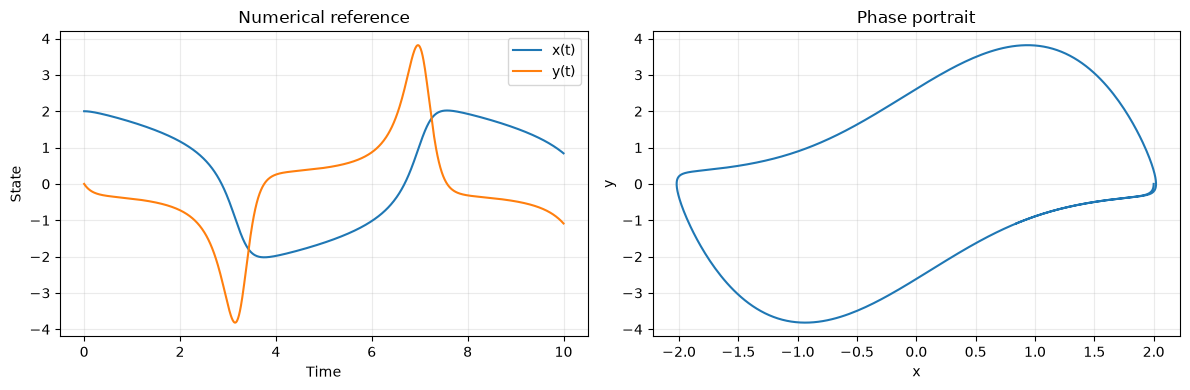

In [2]:
def van_der_pol(t, z):
    x, y = z
    return [y, MU * (1.0 - x*x) * y - x]

t_ref = np.linspace(0.0, T_END, 1001)
solution = solve_ivp(
    van_der_pol,
    (0.0, T_END),
    y0=(2.0, 0.0),
    t_eval=t_ref,
    method="DOP853",
    rtol=1e-10,
    atol=1e-12,
)
assert solution.success, solution.message
reference = solution.y.T

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(t_ref, reference[:, 0], label="x(t)")
axes[0].plot(t_ref, reference[:, 1], label="y(t)")
axes[0].set(xlabel="Time", ylabel="State", title="Numerical reference")
axes[0].legend()
axes[1].plot(reference[:, 0], reference[:, 1])
axes[1].set(xlabel="x", ylabel="y", title="Phase portrait")
for ax in axes: ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 3. Define the PINN and its residual

The network maps physical time to both state variables, $[x_\theta(t),y_\theta(t)]$. Input time is normalized to $[0,1]$, but PyTorch differentiates the output with respect to **physical** $t$, so the chain rule is handled automatically.

$$r_1=\dot{x}_\theta-y_\theta,\qquad r_2=\dot{y}_\theta-\mu(1-x_\theta^2)y_\theta+x_\theta.$$

In [3]:
class PINN(nn.Module):
    def __init__(self, width=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, width), nn.Tanh(),
            nn.Linear(width, width), nn.Tanh(),
            nn.Linear(width, width), nn.Tanh(),
            nn.Linear(width, 2)
        )

    def forward(self, t):
        return self.net(t / T_END)


def residual_squared(model, t):
    t = t.detach().clone().requires_grad_(True)
    states = model(t)
    x = states[:, 0:1]
    y = states[:, 1:2]
    dx_dt = torch.autograd.grad(x, t, torch.ones_like(x), create_graph=True)[0]
    dy_dt = torch.autograd.grad(y, t, torch.ones_like(y), create_graph=True)[0]
    r1 = dx_dt - y
    r2 = dy_dt - MU * (1.0 - x**2) * y + x
    return r1.square() + r2.square()


def ic_loss(model):
    t0 = torch.zeros((1, 1), device=device)
    xy0 = model(t0)
    target = torch.tensor([[2.0, 0.0]], device=device)
    return (xy0 - target).square().sum(dim=1).mean()


def make_collocation_points():
    # Balanced sampling across temporal intervals for both methods.
    starts = torch.arange(N_INTERVALS, device=device, dtype=torch.float32)[:, None]
    dt = T_END / N_INTERVALS
    t = (starts + torch.rand(N_INTERVALS, POINTS_PER_INTERVAL, device=device)) * dt
    return t.reshape(-1, 1)


def interval_residual_losses(model, t):
    # Order of points is time-interval-major, from make_collocation_points().
    return residual_squared(model, t).reshape(N_INTERVALS, POINTS_PER_INTERVAL).mean(dim=1)

## 4. Causal weighting

For time-ordered residual losses $L_i$,

$$w_i=\exp\left(-\varepsilon\sum_{k<i}L_k\right),\qquad
L_\mathrm{causal}=\frac{1}{N_t}\sum_i w_i L_i.$$

**Detach the causal weights:** they control which temporal intervals are emphasized; they should not introduce extra derivatives through the weighting rule. For fair comparison, the baseline uses the same intervals and the same per-interval residual losses, only without weighting.

In [4]:
def causal_loss(interval_losses, epsilon):
    previous = torch.cat([
        torch.zeros_like(interval_losses[:1]),
        torch.cumsum(interval_losses.detach(), dim=0)[:-1]
    ])
    weights = torch.exp(-epsilon * previous)
    return (weights * interval_losses).mean(), weights


def epsilon_schedule(epoch, total_epochs):
    # More conservative at the beginning; progressively increase causality.
    progress = epoch / max(1, total_epochs)
    if progress < 1/4:
        return 10. 
    elif progress < 1/2:
        return 20.
    elif progress < 3/4:
            return 40.
    return 80.

## 5. Train both models with a matched budget

The networks start from identical weights. We also reset the RNG before each run so that each receives the same collocation-point sequence. Only the loss weighting differs.

In [5]:
torch.manual_seed(SEED)
initial_model = PINN().to(device)
initial_state = copy.deepcopy(initial_model.state_dict())


def train_model(use_causal=False):
    model = PINN().to(device)
    model.load_state_dict(initial_state)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {"total": [], "ic": [], "physics": [], "weights": []}
    torch.manual_seed(2026)  # Same collocation-point sequence for both models
    start = time.time()

    for epoch in range(N_EPOCHS):
        t = make_collocation_points()
        optimizer.zero_grad()
        losses = interval_residual_losses(model, t)
        if use_causal:
            pde, weights = causal_loss(losses, epsilon_schedule(epoch, N_EPOCHS))
        else:
            pde = losses.mean()
            weights = torch.ones_like(losses)
        initial = ic_loss(model)
        total = IC_WEIGHT * initial + pde
        total.backward()
        optimizer.step()

        history["total"].append(total.item())
        history["ic"].append(initial.item())
        history["physics"].append(pde.item())
        if epoch % max(1, N_EPOCHS // 100) == 0 or epoch == N_EPOCHS - 1:
            history["weights"].append((epoch, weights.detach().cpu().numpy().copy()))
        if (epoch + 1) % max(1, N_EPOCHS // 5) == 0:
            print(f"{'Causal  ' if use_causal else 'Standard'}: "
                  f"{epoch+1:>5}/{N_EPOCHS} | total={total.item():.5f} "
                  f"| PDE={pde.item():.5f} | min weight={weights.min().item():.3g}")

    print(f"Finished in {time.time() - start:.1f}s")
    return model, history

standard_model, standard_history = train_model(use_causal=False)
causal_model, causal_history = train_model(use_causal=True)

Standard: 40000/200000 | total=0.06054 | PDE=0.05995 | min weight=1
Standard: 80000/200000 | total=0.05749 | PDE=0.05710 | min weight=1
Standard: 120000/200000 | total=0.02212 | PDE=0.02200 | min weight=1
Standard: 160000/200000 | total=0.01885 | PDE=0.01868 | min weight=1
Standard: 200000/200000 | total=0.02333 | PDE=0.02318 | min weight=1
Finished in 248.7s
Causal  : 40000/200000 | total=0.00610 | PDE=0.00600 | min weight=2.29e-24
Causal  : 80000/200000 | total=0.00297 | PDE=0.00293 | min weight=0
Causal  : 120000/200000 | total=0.00321 | PDE=0.00320 | min weight=0
Causal  : 160000/200000 | total=0.00035 | PDE=0.00031 | min weight=0.547
Causal  : 200000/200000 | total=0.00040 | PDE=0.00033 | min weight=0.542
Finished in 237.8s


## 6. Compare predictions with the reference

Measure state error relative to the numerical solution. A low training residual does **not** necessarily imply a low long-horizon trajectory error.

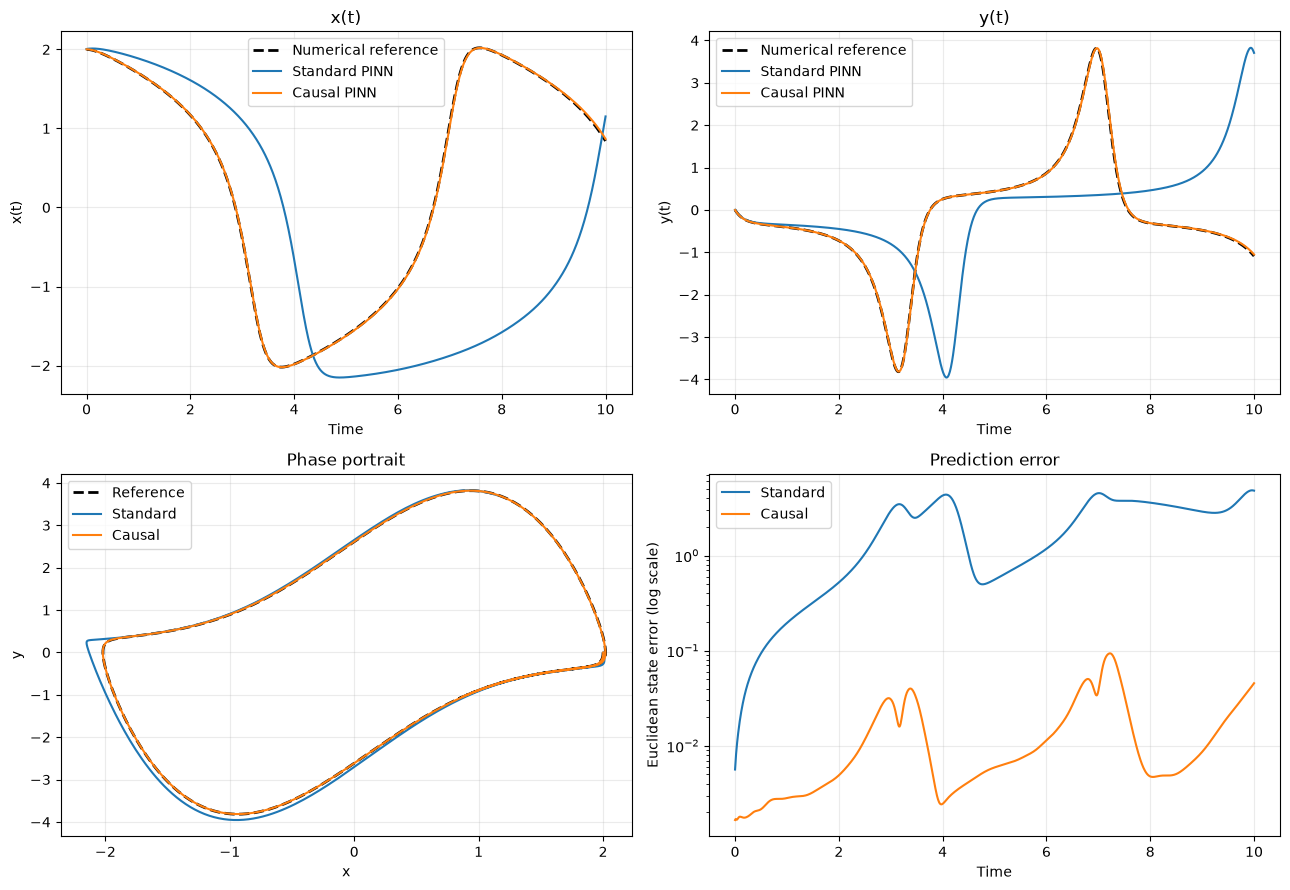

Standard PINN trajectory RMSE: 2.531200398852273
Causal PINN trajectory RMSE:   0.023030399017915607


In [6]:
t_eval = torch.tensor(t_ref[:, None], dtype=torch.float32, device=device)
with torch.no_grad():
    standard_pred = standard_model(t_eval).cpu().numpy()
    causal_pred = causal_model(t_eval).cpu().numpy()

standard_err = np.linalg.norm(standard_pred - reference, axis=1)
causal_err = np.linalg.norm(causal_pred - reference, axis=1)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for j, name in enumerate(("x(t)", "y(t)")):
    ax = axes[0, j]
    ax.plot(t_ref, reference[:, j], 'k--', lw=2, label='Numerical reference')
    ax.plot(t_ref, standard_pred[:, j], label='Standard PINN')
    ax.plot(t_ref, causal_pred[:, j], label='Causal PINN')
    ax.set(xlabel='Time', ylabel=name, title=name)
    ax.legend()

axes[1, 0].plot(reference[:, 0], reference[:, 1], 'k--', lw=2, label='Reference')
axes[1, 0].plot(standard_pred[:, 0], standard_pred[:, 1], label='Standard')
axes[1, 0].plot(causal_pred[:, 0], causal_pred[:, 1], label='Causal')
axes[1, 0].set(xlabel='x', ylabel='y', title='Phase portrait')
axes[1, 0].legend()

axes[1, 1].semilogy(t_ref, np.maximum(standard_err, 1e-12), label='Standard')
axes[1, 1].semilogy(t_ref, np.maximum(causal_err, 1e-12), label='Causal')
axes[1, 1].set(xlabel='Time', ylabel='Euclidean state error (log scale)', title='Prediction error')
axes[1, 1].legend()
for ax in axes.flat: ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print('Standard PINN trajectory RMSE:', np.sqrt(np.mean(standard_err**2)))
print('Causal PINN trajectory RMSE:  ', np.sqrt(np.mean(causal_err**2)))

## 7. Inspect training and causality weights

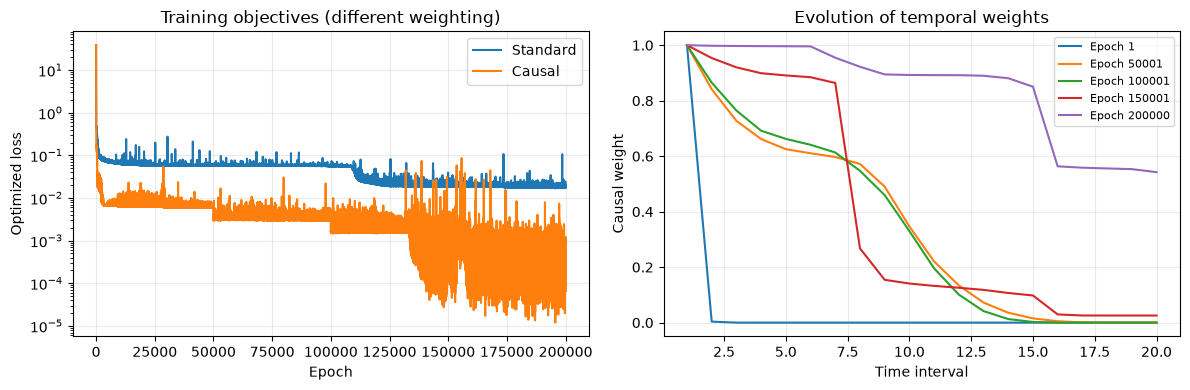

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(standard_history['total'], label='Standard')
axes[0].semilogy(causal_history['total'], label='Causal')
axes[0].set(xlabel='Epoch', ylabel='Optimized loss', title='Training objectives (different weighting)')
axes[0].legend()

selected = np.linspace(0, len(causal_history['weights'])-1, min(5, len(causal_history['weights'])), dtype=int)
for i in selected:
    epoch, w = causal_history['weights'][i]
    axes[1].plot(np.arange(1, N_INTERVALS+1), w, label=f'Epoch {epoch+1}')
axes[1].set(xlabel='Time interval', ylabel='Causal weight', title='Evolution of temporal weights', ylim=(-0.05,1.05))
axes[1].legend(fontsize=8)
for ax in axes: ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()